# 8-SAT: Pretrain QAOA + Amplitude Amplification

主实例为 **10 个变量、176 条子句，每条长度为 8**；主深度 **p=3**，aa-fixed **R=1**，每组 1000 shots。与 `Pretrain_Sparrow.ipynb` 共用原来的 CNF 和训练参数。

恢复之前 3-SAT 的辅助位方法：**每条子句有自己的一位 $a_j$**，共 **10 数据位 + 176 子句辅助位 = 186 位**。所有 $a_j=1$ 时翻相位，随后反计算，将辅助位清零。A、A† 包含完整制备及其逆；$O_0$ 两侧不另加两排 H。

In [1]:
from pathlib import Path
import csv, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector

CNF_NAME = 'instance_8sat_n10_m176_seed20261116.cnf'
K = 8
RESULT_ROOT = 'results/8sat_n10_m176'
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p/'data'/CNF_NAME).is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Open this notebook inside qaoa_aa_3sat.')
OUTPUT = PROJECT/RESULT_ROOT/'circuits'
OUTPUT.mkdir(parents=True, exist_ok=True)
summary = json.loads((PROJECT/RESULT_ROOT/'pretrain/summary.json').read_text(encoding='utf-8'))
N, M = int(summary['n']), int(summary['m'])
assert summary['k'] == K
assert summary['cnf_sha256'] == hashlib.sha256((PROJECT/'data'/CNF_NAME).read_bytes()).hexdigest(), 'Rerun Pretrain for this exact CNF.'
P = 3  # 主 QAOA 的真实层数。
R_FIXED = 1  # 用户指定：执行一整轮 AA。
clauses = []
for line in (PROJECT/'data'/CNF_NAME).read_text(encoding='ascii').splitlines():
    if not line.strip() or line.lstrip().startswith(('c', 'p')):
        continue
    values = list(map(int, line.split()))
    assert len(values) == K+1 and values[-1] == 0
    clauses.append([(abs(v)-1, v > 0) for v in values[:-1]])
assert (N, M, K) == (10, 176, 8) and len(clauses) == M
assert all(len(set(i for i, _ in clause)) == K for clause in clauses)
with (PROJECT/RESULT_ROOT/'pretrain/trained_angles.csv').open(encoding='utf-8-sig', newline='') as f:
    angles = sorted([r for r in csv.DictReader(f) if int(r['p']) == P],
                    key=lambda r: int(r['layer']))
assert [int(r['layer']) for r in angles] == list(range(1, P+1))
gammas = np.array([float(r['gamma_rad']) for r in angles])
betas = np.array([float(r['beta_rad']) for r in angles])

with (PROJECT/RESULT_ROOT/'pretrain/training_runs.csv').open(encoding='utf-8-sig', newline='') as f:
    selected_training = next(row for row in csv.DictReader(f) if int(row['p']) == P)
PRETRAIN_REFERENCE_SUCCESS = float(selected_training['P_sat_exact'])
assert len(gammas) == len(betas) == P == 3 and R_FIXED == 1

In [2]:
# 与 Pretrain_Sparrow 相同的五个函数；直接定义，便于查看和跳转。

def greedy_clause_colors(clauses):
    """A valid greedy coloring, not a claim of minimum chromatic number."""
    batches = []
    used = []
    for j, clause in enumerate(clauses):
        variables = {i for i, _ in clause}
        for b, occupied in enumerate(used):
            if not variables & occupied:
                batches[b].append(j)
                occupied.update(variables)
                break
        else:
            batches.append([j]); used.append(set(variables))
    return batches


def phaser_circuit(n, clauses, gamma):
    qc = QuantumCircuit(n, name='phaser')
    for batch in greedy_clause_colors(clauses):
        for j in batch:
            clause = clauses[j]
            positive = [i for i, sign in clause if sign]
            variables = [i for i, _ in clause]
            if positive: qc.x(positive)
            # Paper Eq. (4): H_C = -#SAT = #UNSAT-m; mark failure with -gamma.
            qc.mcp(-float(gamma), variables[:-1], variables[-1])
            if positive: qc.x(positive)
    # e^{-i gamma H_C} = e^{+i gamma m} e^{-i gamma #UNSAT}.
    qc.global_phase += float(gamma) * len(clauses)
    return qc


def mixer_circuit(n, beta):
    qc = QuantumCircuit(n, name='mixer')
    qc.rx(float(beta), range(n))  # H_M = (1/2) sum X, paper Eq. (3).
    return qc


def qaoa_circuit(n, clauses, gammas, betas, boxed=False):
    qc = QuantumCircuit(n, name='A=U H')
    qc.h(range(n))
    for layer, (gamma, beta) in enumerate(zip(gammas, betas), start=1):
        ph = phaser_circuit(n, clauses, gamma)
        mix = mixer_circuit(n, beta)
        if boxed:
            qc.append(ph.to_gate(label=f'phaser {layer}: gamma={gamma:.3f}'), range(n))
            qc.append(mix.to_gate(label=f'mixer {layer}: beta={beta:.3f}'), range(n))
        else:
            qc.compose(ph, inplace=True)
            qc.compose(mix, inplace=True)
    qc.metadata = {'qaoa_parameters': {'gammas': list(map(float, gammas)), 'betas': list(map(float, betas))}}
    return qc


def expose_global_phase(circuit, label):
    """把电路顶部的全局相位，等价地显示成跨越全部量子线的方块。"""
    visible = circuit.copy()
    angle = float(visible.global_phase)
    visible.global_phase = 0  # 移到下面的方块中，避免重复乘一次相位。

    phase_identity = QuantumCircuit(visible.num_qubits, name='global_phase')
    phase_identity.global_phase = angle  # 这个方块的全部作用：e^(i*angle) I。
    visible.append(phase_identity.to_gate(label=label), visible.qubits)
    return visible

In [3]:
batches = greedy_clause_colors(clauses)
clause_order = [j for batch in batches for j in batch]
def clause_latex(j):
    return r' \lor '.join(('' if sign else r'\neg ')+f'x_{{{i+1}}}' for i,sign in clauses[j])
display(Markdown('$$'+r'\begin{aligned}'+r'\\'.join(
    rf'C_{{{j+1}}}&={clause_latex(j)}' for j in range(6))+r'\end{aligned}'+'$$'))
print(f'DIMACS: p cnf {N} {M}; k={K}. Showing first 6 of {M} actual clauses.')
print(f'Clause batches: {len(batches)}. Any two 8-variable clauses share at least 6 variables.')
assert len(batches)==M and sorted(clause_order)==list(range(M))

$$\begin{aligned}C_{1}&=\neg x_{3} \lor \neg x_{4} \lor \neg x_{5} \lor x_{6} \lor \neg x_{7} \lor x_{8} \lor x_{9} \lor x_{10}\\C_{2}&=\neg x_{1} \lor \neg x_{4} \lor \neg x_{5} \lor \neg x_{6} \lor \neg x_{7} \lor x_{8} \lor x_{9} \lor \neg x_{10}\\C_{3}&=\neg x_{2} \lor \neg x_{3} \lor \neg x_{4} \lor \neg x_{5} \lor x_{6} \lor \neg x_{7} \lor x_{8} \lor \neg x_{10}\\C_{4}&=x_{2} \lor \neg x_{3} \lor x_{4} \lor x_{5} \lor \neg x_{6} \lor x_{7} \lor \neg x_{8} \lor x_{10}\\C_{5}&=x_{1} \lor \neg x_{2} \lor \neg x_{4} \lor \neg x_{5} \lor \neg x_{7} \lor \neg x_{8} \lor x_{9} \lor x_{10}\\C_{6}&=x_{1} \lor \neg x_{2} \lor \neg x_{3} \lor x_{4} \lor \neg x_{5} \lor \neg x_{6} \lor \neg x_{9} \lor \neg x_{10}\end{aligned}$$

DIMACS: p cnf 10 176; k=8. Showing first 6 of 176 actual clauses.
Clause batches: 176. Any two 8-variable clauses share at least 6 variables.


## 1. 与 Pretrain 相同的三层 QAOA

每层实际包含 176 个 8-literal 子句相位门和 10 个 $R_x(\beta)$。主图显示三层模块顺序；下面另外展开真实 $C_1$ 的 8 位相位门。完整 phaser 门序保存在 `A` 中。

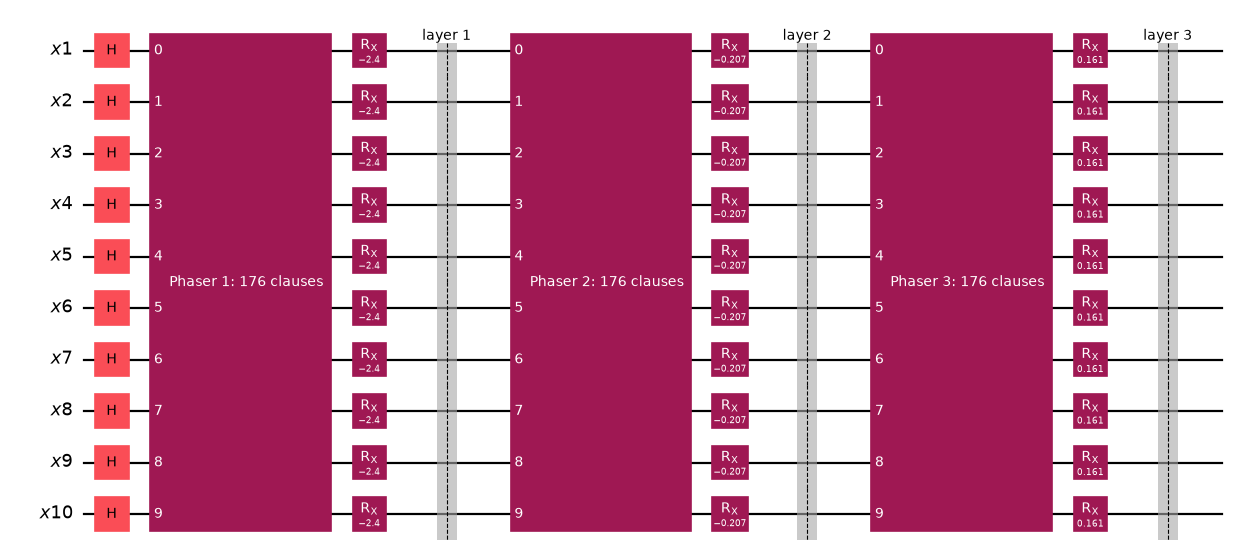

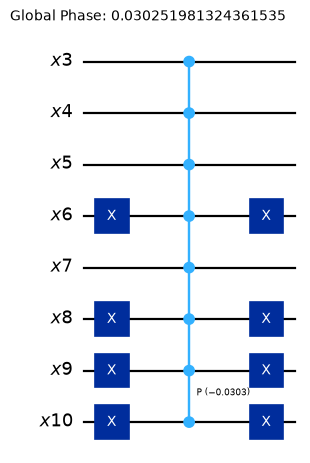

In [4]:
A = qaoa_circuit(N, clauses, gammas, betas, boxed=False)
U = QuantumCircuit(N, name='QAOA U')
U.global_phase=A.global_phase
for inst in A.data[N:]:
    U.append(inst.operation,[A.find_bit(q).index for q in inst.qubits])
qaoa_gate=U.to_gate(label=f'QAOA U (p={P})')
preparation_gate=A.to_gate(label=f'QAOA A (p={P})')
inverse_gate=A.inverse().to_gate(label=f'QAOA A dagger (p={P})')
qaoa_visible=QuantumCircuit(*[QuantumRegister(1,f'x{i+1}') for i in range(N)],name='8-SAT QAOA')
qaoa_visible.h(range(N))
for layer,(gamma,beta) in enumerate(zip(gammas,betas),1):
    ph=phaser_circuit(N,clauses,gamma)
    qaoa_visible.append(ph.to_gate(label=f'Phaser {layer}: {M} clauses'),range(N))
    qaoa_visible.compose(mixer_circuit(N,beta),inplace=True)
    qaoa_visible.barrier(label=f'layer {layer}')
fig=qaoa_visible.draw('mpl',fold=-1,scale=.8)
fig.savefig(OUTPUT/'01_Pretrain_QAOA.png',dpi=160,bbox_inches='tight')
fig.savefig(OUTPUT/'01_Pretrain_QAOA.svg',bbox_inches='tight')
display(fig);plt.close(fig)
local_clause=[[(q,sign) for q,(_,sign) in enumerate(clauses[0])]]
first_clause=phaser_circuit(K,local_clause,float(gammas[0]))
named_clause=QuantumCircuit(*[QuantumRegister(1,f'x{i+1}') for i,_ in clauses[0]])
named_clause.compose(first_clause,inplace=True)
first_clause=named_clause
fig=first_clause.draw('mpl',fold=-1,scale=.8)
fig.savefig(OUTPUT/'01b_actual_C1_phaser.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)

## 2. 恢复原来的辅助位：一条子句对应一位

$$a_1\leftrightarrow C_1,\quad a_2\leftrightarrow C_2,\quad\ldots,\quad a_{176}\leftrightarrow C_{176}.$$

每位从 0 开始，计算后 $a_j=C_j(x)$：满足为 1，不满足为 0。以 $C_j$ 为例，先对正文字所在数据位施加 X，使“该子句失败”的图样变成全 1；用 8 个控制位的 MCX 将失败指示写入 $a_j$，撤销数据位的 X，再对 $a_j$ 施加 X，得到满足指示。

$$|x,0^{176}\rangle\xrightarrow{\mathrm{compute}}
|x,C_1(x),\ldots,C_{176}(x)\rangle
\xrightarrow{\mathrm{MCZ}}(-1)^{\prod_j C_j(x)}|x,C_1(x),\ldots,C_{176}(x)\rangle
\xrightarrow{\mathrm{uncompute}}(-1)^{\prod_j C_j(x)}|x,0^{176}\rangle.$$

中间的 MCZ 用最后一个辅助位上的 H–MCX–H 实现：只有全部 176 个辅助位为 1 时才翻相位。没有计数器、加法器或额外的总 flag。

下面展开**实际前三条子句的计算片段**，显示各自的 a1、a2、a3；相位标记始终检查全部 176 位，片段不代替完整 oracle。完整 186 位 Qiskit 电路另存为 SVG 和文本；运行下面单元格即可重新构建电路对象。

$$O_0=I-2|0^{10}\rangle\langle0^{10}|,\qquad A=UH^{\otimes10},\qquad G=AO_0A^\dagger O_C.$$

[完整 186 位电路（SVG，可放大）](../results/8sat_n10_m176/circuits/02_QAOA_AA.svg) · [完整门序（文本）](../results/8sat_n10_m176/circuits/02_QAOA_AA.txt)

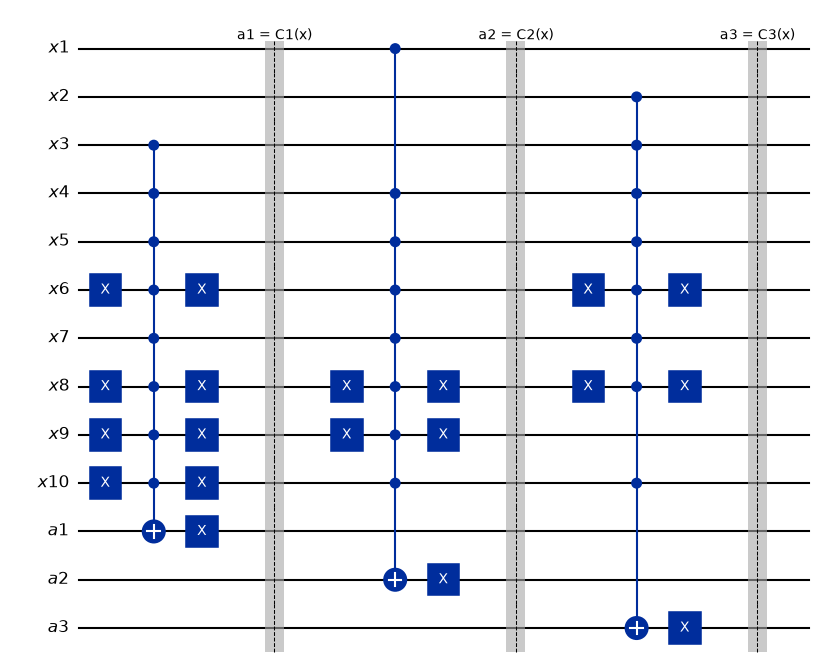

Full actual circuit: 186 qubits = 10 data + 176 separate clause flags.
a1 stores C1, a2 stores C2, ..., a176 stores C176; all return to 0 after OC.


In [5]:
def clause_compute(n, clause, label='OR_clause'):
    """|x,a> -> |x, a XOR C_j(x)>; last qubit is this clause's own flag."""
    qc = QuantumCircuit(n+1, name=label)
    positive = [i for i, sign in clause if sign]
    if positive: qc.x(positive)
    qc.mcx([i for i, _ in clause], n)
    if positive: qc.x(positive)
    qc.x(n)  # Complement the failure indicator: a XOR (1-C_j) XOR 1.
    return qc

def zero_reflection(n):
    qc = QuantumCircuit(n, name='O0')
    qc.x(range(n)); qc.h(n-1)
    qc.mcx(list(range(n-1)), n-1)
    qc.h(n-1); qc.x(range(n))
    return qc

xregs = [QuantumRegister(1, f'x{i+1}') for i in range(N)]
flag_registers = [QuantumRegister(1, f'a{j+1}') for j in range(M)]
data = [r[0] for r in xregs]
flags = [r[0] for r in flag_registers]
compute = QuantumCircuit(*xregs, *flag_registers, name='Compute clause flags')
clause_modules = []
for j in range(M):
    module = clause_compute(N, clauses[j], label=f'C{j+1}')
    clause_modules.append(module)
    # Compose the gates directly; each clause writes to its own a_j.
    compute.compose(module, qubits=[*data, flags[j]], inplace=True)
uncompute = compute.inverse()

mark = QuantumCircuit(M, name='All clause flags are 1')
mark.h(M-1)
mark.mcx(list(range(M-1)), M-1)
mark.h(M-1)  # A 176-qubit MCZ, no extra flag qubit.

OC = compute.copy(name='OC: compute-mark-uncompute')
OC.barrier(label='all clauses satisfied?')
OC.compose(mark, qubits=flags, inplace=True)
OC.barrier(label='restore all a_j to 0')
OC.compose(uncompute, inplace=True)
O0 = zero_reflection(N)

full = QuantumCircuit(*xregs, *flag_registers, name='8-SAT QAOA plus one AA')
full.h(data); full.append(qaoa_gate, data)
full.barrier(label='O_C: compute')
full.compose(OC, inplace=True)
full.barrier(label='A dagger')
full.append(inverse_gate, data)
full.barrier(label='O_0')
full.compose(O0, qubits=data, inplace=True)
full.barrier(label='A')
full.append(preparation_gate, data)
measured = full.copy()
out = ClassicalRegister(N, 'out'); measured.add_register(out)
measured.measure(data, out)
(OUTPUT/'02_QAOA_AA.txt').write_text(str(measured.draw('text', fold=160)), encoding='utf-8')

# This is the complete actual 186-wire circuit, without hiding any OC gates.
# A low raster DPI keeps the overview manageable; SVG preserves every detail.
fig = measured.draw('mpl', fold=-1, scale=.32, cregbundle=True, idle_wires=True,
                    style={'dpi':20})
fig.savefig(OUTPUT/'02_QAOA_AA.svg', bbox_inches='tight')
fig.savefig(OUTPUT/'02_QAOA_AA.png', dpi=12, bbox_inches='tight')
plt.close(fig)
display(Markdown('[完整 186 位电路（SVG，可放大）](../'+RESULT_ROOT+
                 '/circuits/02_QAOA_AA.svg) · [完整门序（文本）](../'+RESULT_ROOT+
                 '/circuits/02_QAOA_AA.txt)'))

fragment = QuantumCircuit(*xregs, *flag_registers[:3], name='Actual C1-C3 compute fragment')
for j in range(3):
    fragment.compose(clause_modules[j], qubits=[*data, flags[j]], inplace=True)
    fragment.barrier(label=f'a{j+1} = C{j+1}(x)')
fig = fragment.draw('mpl', fold=-1, scale=.75, idle_wires=True)
fig.savefig(OUTPUT/'02b_clause_flags_compute.png', dpi=160, bbox_inches='tight')
fig.savefig(OUTPUT/'02b_clause_flags_compute.svg', bbox_inches='tight')
display(fig); plt.close(fig)
print(f'Full actual circuit: {full.num_qubits} qubits = {N} data + {M} separate clause flags.')
print('a1 stores C1, a2 stores C2, ..., a176 stores C176; all return to 0 after OC.')

## 3. 核验：逐条子句、全部输入与辅助位清零

先检查每个子句模块的全部 512 种局部输入（8 数据位 + 1 辅助位），确认它执行 $a_j\mapsto a_j\oplus C_j(x)$。

然后对全部 1024 个数据赋值追踪实际 186 位门序；基态编号使用 Python 大整数。中间的实际 H–MCX–H 用稀疏振幅演化核验，最终确认只有满足解被翻相位、全部 176 个辅助位回到 0。186 位电路只会占据至多 2048 个非零基态，无需申请 $2^{186}$ 个振幅。

再用等价的 10 数据位表示和真实 A、A† 核验一轮 AA 的全部复振幅。后面的统计和 CPU 计时仍使用这一等价表示。

In [6]:
psi = Statevector.from_instruction(A).data
visible_error = float(np.max(np.abs(Statevector.from_instruction(qaoa_visible).data-psi)))
assert visible_error < 1e-9
good = np.array([all(any(bool((s>>i)&1)==sign for i,sign in cl) for cl in clauses)
                 for s in range(1<<N)])

def permute_basis(circuit, indices):
    """Track the actual X/controlled-X gates, using unbounded Python integers."""
    values = [int(v) for v in indices]
    for inst in circuit.data:
        op = inst.operation
        if op.name == 'barrier': continue
        assert op.name in ('x', 'cx', 'ccx', 'mcx'), op.name
        q = [circuit.find_bit(t).index for t in inst.qubits]
        mask = sum(1<<c for c in q[:-1]); flip = 1<<q[-1]
        values = [v^flip if (v&mask)==mask else v for v in values]
    return values

for j, clause in enumerate(clauses):
    local = clause_compute(len(clause), [(i, sign) for i, (_, sign) in enumerate(clause)])
    initial = list(range(1<<(len(clause)+1)))
    actual = permute_basis(local, initial)
    expected = [v ^ (int(any(bool((v>>i)&1)==sign for i,(_,sign) in enumerate(clause)))
                     <<len(clause)) for v in initial]
    assert actual == expected, f'C{j+1} truth table'

inputs = list(range(1<<N))
computed = permute_basis(compute, inputs)
expected = [s | (sum(int(any(bool((s>>i)&1)==sign for i,sign in cl))<<j
                    for j,cl in enumerate(clauses))<<N) for s in inputs]
assert computed == expected
assert permute_basis(uncompute, computed) == inputs

def sparse_mark(circuit, state, wire_map):
    """Apply the actual H-MCX-H marker on a sparse superposition."""
    state = dict(state)
    for inst in circuit.data:
        q = [wire_map[circuit.find_bit(t).index] for t in inst.qubits]
        if inst.operation.name == 'h':
            flip = 1<<q[0]; result = {}
            for v, amplitude in state.items():
                low = v & ~flip; high = low | flip
                result[low] = result.get(low, 0j) + amplitude/np.sqrt(2)
                result[high] = result.get(high, 0j) + (-1 if v&flip else 1)*amplitude/np.sqrt(2)
            state = {v:a for v,a in result.items() if abs(a)>1e-14}
        else:
            assert inst.operation.name in ('x','cx','ccx','mcx')
            mask = sum(1<<c for c in q[:-1]); flip = 1<<q[-1]
            state = {v^flip if (v&mask)==mask else v:a for v,a in state.items()}
    return state

# A uniform input tests every branch even if a trained amplitude happens to be zero.
uniform = 1/np.sqrt(1<<N)
marked_sparse = sparse_mark(mark, {v:uniform for v in computed}, list(range(N,N+M)))
keys = list(marked_sparse)
restored = permute_basis(uncompute, keys)
oracle_data = np.zeros(1<<N, dtype=complex)
leakage = 0.
for v, original in zip(restored, keys):
    if v >= 1<<N: leakage += abs(marked_sparse[original])**2
    else: oracle_data[v] += marked_sparse[original]
oracle_sign = np.where(good, -1., 1.)
oracle_error = float(np.max(np.abs(oracle_data-uniform*oracle_sign)))
assert oracle_error < 1e-10 and leakage < 1e-12
assert full.num_qubits == N+M == 186
assert full.count_ops().get('h',0) == N+4

P0 = float(np.sum(np.abs(psi[good])**2))
assert np.isclose(P0, PRETRAIN_REFERENCE_SUCCESS, atol=1e-9)
marked = Statevector(psi*oracle_sign).evolve(A.inverse())
marked.data[0] *= -1
final_data = marked.evolve(A).data
reference = psi*oracle_sign
reference -= 2*psi*np.vdot(psi,reference)
aa_error = float(np.max(np.abs(final_data-reference)))
assert aa_error < 1e-8
P1 = float(np.sum(np.abs(final_data[good])**2))
assert np.isclose(P1, np.sin(3*np.arcsin(np.sqrt(P0)))**2, atol=1e-8)
verification = {'n':N, 'm':M, 'k':K, 'p':P, 'total_circuit_qubits':full.num_qubits,
    'clause_ancillas':M, 'counter_bits':0, 'extra_global_flags':0,
    'ancilla_method':'one satisfied-clause flag per clause; compute-MCZ-uncompute',
    'work_clean_for_all_1024_inputs':True, 'all_clause_truth_tables_verified':True,
    'oracle_verification':'actual X/MCX permutations plus sparse H-MCX-H on all 1024 inputs',
    'oracle_complex_amplitude_error':oracle_error, 'flag_leakage':leakage,
    'QAOA_complex_amplitude_error':visible_error, 'AA_complex_amplitude_error':aa_error,
    'P0':P0, 'P1':P1, 'CNF':CNF_NAME, 'cnf_sha256':summary['cnf_sha256'],
    'clause_mapping':[{'clause':j+1, 'flag':f'a{j+1}',
                       'literals':[i+1 if sign else -(i+1) for i,sign in cl]}
                      for j,cl in enumerate(clauses)]}
(OUTPUT/'verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
print('PASS: 176 clause truth tables; all 1024 inputs; actual mark; all flags clean.')
print(f'Oracle error={oracle_error:.3g}; AA error={aa_error:.3g}; P0={P0:.9f}; P1={P1:.9f}')

PASS: 176 clause truth tables; all 1024 inputs; actual mark; all flags clean.
Oracle error=3.47e-18; AA error=5.74e-13; P0=0.933622139; P1=0.503664347


## 4. 实验设置与函数定义

同一份 $n=10,m=176,k=8$ CNF；每条子句仍含 8 个文字。三个深度分别训练，主设置 p=3、aa-fixed R=1。每组 1000 shots，Sparrow 1000 次独立运行，扫描 R=0…12。

本次只把 oracle 换回每子句一辅助位；CNF、训练角度和数据位上的 oracle 相位完全相同，因此保留已有训练、统计和实测计时。

计时采用精确 NumPy 数据位态矢量（预编译每层对角相位）与原生 Sparrow 进程时间；完整 186 位门序用于逻辑核验，未用 186 位稠密模拟计时。两者都不是量子硬件时间。这里的 186 是理想电路的量子线数，未将 MCX 编译到特定门集，也不包含容错。

In [7]:
import os, re, subprocess, tempfile, time, sys, html, random
from datetime import datetime
from zoneinfo import ZoneInfo
from scipy.optimize import minimize
import scipy, qiskit
from matplotlib.patches import Patch

EXPERIMENT = PROJECT/RESULT_ROOT/'experiments'
FIGURES, TABLES = EXPERIMENT/'figures', EXPERIMENT/'data'
for directory in (FIGURES, TABLES):
    directory.mkdir(parents=True, exist_ok=True)
SHOTS = 1000
SPARROW_RUNS = 1000
SHOT_SEED, TRAIN_SEED = 5109, 2410
RESTARTS, MAXITER = 3, 100
R_MAX = 12
SWEEP_N, SWEEP_INSTANCES = [8, 9, 10, 11, 12], 3
SWEEP_SPARROW_RUNS, TIMING_REPEATS = 30, 9
COLORS = {'QAOA': '#245b8b', 'AA fixed': '#c96d2e',
          'AA adjusted': '#007c83', 'Sparrow': '#626b73', 'non-SAT': '#b6bcc1'}
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
MEASURED_AT = datetime.now(ZoneInfo('Asia/Shanghai')).isoformat()
SPARROW_EXE = Path(os.environ.get('SPARROW_EXE',
    PROJECT.parent/'classical_solvers/sparrow/bin/sparrow.exe'))
if not SPARROW_EXE.is_file():
    SPARROW_EXE = Path('D:/桌面/hkust/urop/code/classical_solvers/sparrow/bin/sparrow.exe')
if not SPARROW_EXE.is_file():
    raise FileNotFoundError('Set SPARROW_EXE to the installed Sparrow executable.')

def save_plot(fig, name):
    fig.savefig(FIGURES/f'{name}.png', dpi=170, bbox_inches='tight')
    fig.savefig(FIGURES/f'{name}.svg', bbox_inches='tight')
    display(fig)
    plt.close(fig)

def write_rows(name, rows):
    rows = list(rows)
    if not rows:
        return
    with (TABLES/name).open('w', encoding='utf-8-sig', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def show_rows(rows):
    rows = list(rows)
    if not rows:
        return
    keys = list(rows[0])
    header = ''.join(f'<th>{html.escape(str(k))}</th>' for k in keys)
    body = ''.join('<tr>'+''.join(f'<td>{html.escape(str(row[k]))}</td>' for k in keys)+'</tr>'
                   for row in rows)
    display(Markdown('<table><thead><tr>'+header+'</tr></thead><tbody>'+body+'</tbody></table>'))

def bitstring(value, n=N):
    return format(int(value), f'0{n}b')  # Left to right: external x_n ... x_1.

def is_solution(value, formula):
    return all(any(bool((int(value) >> i) & 1) == sign for i, sign in clause)
               for clause in formula)

def read_rows(path):
    with path.open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

def wilson(successes, total):
    z = 1.959963984540054
    frequency = successes/total
    denominator = 1+z*z/total
    center = (frequency+z*z/(2*total))/denominator
    radius = z*np.sqrt(frequency*(1-frequency)/total+z*z/(4*total*total))/denominator
    return max(0., float(center-radius)), min(1., float(center+radius))

def sample_counts(state, shots, seed):
    probability = np.abs(state)**2
    probability /= probability.sum()
    return np.random.default_rng(seed).multinomial(shots, probability)

def amplify_state(state, sat_mask, rounds):
    initial = np.asarray(state, dtype=complex)
    current = initial.copy()
    for _ in range(int(rounds)):
        current[sat_mask] *= -1
        current -= 2*initial*np.vdot(initial, current)
    return current

def aa_success(initial_success, rounds):
    theta = np.arcsin(np.sqrt(np.clip(initial_success, 0., 1.)))
    return np.sin((2*np.asarray(rounds)+1)*theta)**2

In [8]:
def paper_cost_diagonal(n, clauses):
    """Diagonal of the paper's H_C = -sum_j C_j, Eq. (4).

    Evaluate satisfied clauses directly. The violation count remains only a
    diagnostic; it is not a second Hamiltonian or the optimizer's objective.
    """
    states = np.arange(1 << n, dtype=np.int64)
    cost_diagonal = np.zeros(1 << n, dtype=np.int64)
    for clause in clauses:
        satisfied = np.zeros(1 << n, dtype=bool)
        for i, positive in clause:
            bit = ((states >> i) & 1).astype(bool)
            satisfied |= bit if positive else ~bit
        cost_diagonal -= satisfied
    return cost_diagonal


def qaoa_state(n, cost_diagonal, gammas, betas):
    """Fast exact NumPy evolution, independently checked against Qiskit.

    Use the complete H_C diagonal from paper Eq. (4), including its constant
    phase. Its complex amplitudes are checked directly against Qiskit.
    """
    state = np.full(1 << n, 1 / np.sqrt(1 << n), dtype=complex)
    for gamma, beta in zip(gammas, betas):
        state *= np.exp(-1j * gamma * cost_diagonal)
        co, si = np.cos(beta/2), -1j*np.sin(beta/2)
        for q in range(n):
            block = state.reshape(-1, 2, 1 << q)
            lo, hi = block[:, 0, :].copy(), block[:, 1, :].copy()
            block[:, 0, :] = co*lo + si*hi
            block[:, 1, :] = si*lo + co*hi
    return state


def train_qaoa(n, cost_diagonal, good, p, seed, restarts=3, maxiter=100, warm=None):
    # 本地经典优化：固定种子，便于复现初始角度。
    rng = np.random.default_rng(seed)
    history = []
    attempts = []
    initial_points = []
    if warm is not None:
        old_p = len(warm['gammas'])
        initial_points.append(np.r_[warm['gammas'], np.zeros(p-old_p),
                                    warm['betas'], np.zeros(p-old_p)])
    while len(initial_points) < restarts:
        initial_points.append(np.r_[-rng.uniform(0, 2*np.pi, p),
                                    rng.uniform(-np.pi, np.pi, p)])
    def objective(params):
        # 前 p 个数是 gamma，后 p 个数是 beta。
        state = qaoa_state(n, cost_diagonal, params[:p], params[p:])
        probabilities = np.abs(state)**2
        loss = float(probabilities @ cost_diagonal)  # 论文 H_C 的期望值
        history.append((len(history)+1, loss, float(probabilities[good].sum())))
        return loss
    start = time.perf_counter()
    best = None
    for initial in initial_points:
        # Preserve initial candidate, so warm-start nesting cannot worsen cost.
        loss0 = objective(initial)
        result = minimize(objective, initial, method='L-BFGS-B',
                          options={'maxiter': maxiter, 'ftol': 1e-10, 'maxls': 30})
        chosen = result.x if result.fun <= loss0 else initial
        loss = min(float(result.fun), loss0)
        attempts.append({'loss': loss, 'converged': bool(result.success),
                         'message': str(result.message), 'nfev': int(result.nfev)})
        if best is None or loss < best[0]: best = (loss, chosen.copy())
    train_time = time.perf_counter()-start
    gammas, betas = best[1][:p], best[1][p:]
    state = qaoa_state(n, cost_diagonal, gammas, betas)
    return {'p':p, 'gammas':gammas, 'betas':betas, 'state':state,
            'expected_cost':best[0], 'success':float(np.abs(state[good]) @ np.abs(state[good])),
            'train_time_s':train_time, 'nfev':len(history),
            'history':np.asarray(history), 'attempts':attempts}

In [9]:
def cnf_text(n, formula):
    lines = [f'p cnf {n} {len(formula)}']
    lines += [' '.join(str(i+1 if sign else -(i+1)) for i, sign in clause)+' 0'
              for clause in formula]
    return '\n'.join(lines)+'\n'

def run_native_sparrow(n, formula, cnf_path, seed):
    command = [str(SPARROW_EXE), '--randomc', '1', '-a', '--runs', '1',
               '--maxflips', '1000000', str(cnf_path), str(int(seed))]
    start = time.perf_counter_ns()
    try:
        proc = subprocess.run(command, capture_output=True, text=True, encoding='utf-8',
                              errors='replace', timeout=5, check=False,
                              creationflags=getattr(subprocess, 'CREATE_NO_WINDOW', 0))
    except subprocess.TimeoutExpired:
        return {'seed': int(seed), 'status': 'UNKNOWN', 'state': None, 'bitstring': '',
                'valid': False, 'process_s': (time.perf_counter_ns()-start)*1e-9,
                'cpu_s': None, 'flips': None, 'stdout': '', 'exit_code': None}
    elapsed = (time.perf_counter_ns()-start)*1e-9
    if proc.returncode not in (0, 10):
        raise RuntimeError(f'Sparrow exited {proc.returncode}: {proc.stderr}')
    sat = bool(re.search(r'^\s*s\s+SATISFIABLE\s*$', proc.stdout, re.MULTILINE))
    bits = [None]*n
    if sat:
        for line in proc.stdout.splitlines():
            if not line.lstrip().startswith('v '):
                continue
            for literal in map(int, line.split()[1:]):
                if literal == 0:
                    break
                i, value = abs(literal)-1, int(literal > 0)
                if not 0 <= i < n or bits[i] not in (None, value):
                    raise RuntimeError('Invalid Sparrow model.')
                bits[i] = value
        if None in bits:
            raise RuntimeError('Sparrow model is incomplete.')
    state = sum(value << i for i, value in enumerate(bits)) if sat else None
    valid = sat and is_solution(state, formula)
    if sat and not valid:
        raise RuntimeError('Sparrow output fails the original clauses.')
    match = re.search(r'Total CPU Time\s*:\s*([\d.eE+-]+)', proc.stdout+'\n'+proc.stderr,
                      flags=re.IGNORECASE)
    flip_match = re.search(r'totalFlips\s*:\s*(\d+)', proc.stdout+'\n'+proc.stderr)
    return {'seed': int(seed), 'status': 'SAT' if valid else 'UNKNOWN', 'state': state,
            'bitstring': bitstring(state, n) if valid else '', 'valid': valid,
            'process_s': elapsed, 'cpu_s': float(match.group(1)) if match else None,
            'flips': int(flip_match.group(1)) if flip_match else None,
            'stdout': proc.stdout, 'exit_code': proc.returncode}

def solver_batch(n, formula, runs, seed_base=1, progress=False):
    root = Path(tempfile.gettempdir()).resolve()
    if not str(root).isascii():
        raise RuntimeError('Sparrow needs an ASCII-only temporary path.')
    with tempfile.TemporaryDirectory(prefix='sat_meeting_', dir=root) as folder:
        path = Path(folder)/'instance.cnf'
        path.write_text(cnf_text(n, formula), encoding='ascii')
        for warm in range(3):
            run_native_sparrow(n, formula, path, 900000+warm)
        results = []
        for j in range(runs):
            results.append(run_native_sparrow(n, formula, path, seed_base+j))
            if progress and (j+1) % 250 == 0:
                print(f'Sparrow: {j+1}/{runs} verified runs', flush=True)
    return results

def generate_satisfiable(n,m,seed):
    if n<K:raise ValueError('An 8-SAT clause needs at least 8 distinct variables.')
    rng=random.Random(seed)
    for attempt in range(10000):
        seen=set();formula=[]
        while len(formula)<m:
            clause=tuple((i,bool(rng.randrange(2))) for i in sorted(rng.sample(range(n),K)))
            if clause not in seen:seen.add(clause);formula.append(list(clause))
        if np.any(paper_cost_diagonal(n,formula)==-m):return formula
    raise RuntimeError('No satisfiable random instance found.')

def apply_single_qubit(state,q,co,si):
    block=state.reshape(-1,2,1<<q)
    lo,hi=block[:,0,:].copy(),block[:,1,:].copy()
    block[:,0,:]=co*lo+si*hi
    block[:,1,:]=si*lo+co*hi

def apply_hadamards(state,n):
    for q in range(n):
        block=state.reshape(-1,2,1<<q)
        lo,hi=block[:,0,:].copy(),block[:,1,:].copy()
        block[:,0,:]=(lo+hi)/np.sqrt(2)
        block[:,1,:]=(lo-hi)/np.sqrt(2)

def apply_preparation(state,n,phases,betas,inverse=False):
    state=np.asarray(state,dtype=complex).copy()
    if inverse:
        for phase,beta in reversed(list(zip(phases,betas))):
            for q in range(n):apply_single_qubit(state,q,np.cos(beta/2),1j*np.sin(beta/2))
            state*=phase.conj()
        apply_hadamards(state,n)
    else:
        apply_hadamards(state,n)
        for phase,beta in zip(phases,betas):
            state*=phase
            for q in range(n):apply_single_qubit(state,q,np.cos(beta/2),-1j*np.sin(beta/2))
    return state

def simulator_attempt(n,phases,betas,sat_mask,rounds,formula,rng):
    # Exact compiled CPU statevector. All m clauses contribute to each phase array.
    state=np.zeros(1<<n,dtype=complex);state[0]=1
    state=apply_preparation(state,n,phases,betas)
    for _ in range(int(rounds)):
        state[sat_mask]*=-1
        state=apply_preparation(state,n,phases,betas,inverse=True)
        state[0]*=-1
        state=apply_preparation(state,n,phases,betas)
    probability=np.abs(state)**2;probability/=probability.sum()
    value=int(rng.choice(len(probability),p=probability))
    return value,is_solution(value,formula)

def time_simulator(circuit,sat_mask,rounds,formula,seed,repeats=TIMING_REPEATS):
    meta=circuit.metadata['qaoa_parameters']
    n=circuit.num_qubits
    diagonal=paper_cost_diagonal(n,formula)
    phases=[np.exp(-1j*g*diagonal) for g in meta['gammas']]
    bs=meta['betas']
    rng=np.random.default_rng(seed)
    simulator_attempt(n,phases,bs,sat_mask,rounds,formula,rng)
    durations=[]
    for _ in range(repeats):
        start=time.perf_counter_ns()
        simulator_attempt(n,phases,bs,sat_mask,rounds,formula,rng)
        durations.append((time.perf_counter_ns()-start)*1e-9)
    return durations


def crossover_points(sizes, method_seconds, sparrow_seconds):
    """Interpolate crossings in log-time between measured sizes; return n and seconds."""
    sizes = np.asarray(sizes, dtype=float)
    method_seconds = np.asarray(method_seconds, dtype=float)
    sparrow_seconds = np.asarray(sparrow_seconds, dtype=float)
    difference = np.log(method_seconds)-np.log(sparrow_seconds)
    points = []
    for i in range(len(sizes)-1):
        if abs(difference[i]) < 1e-12:
            points.append({'n': float(sizes[i]), 'time_s': float(sparrow_seconds[i])})
        elif difference[i]*difference[i+1] < 0:
            fraction = -difference[i]/(difference[i+1]-difference[i])
            size = sizes[i]+fraction*(sizes[i+1]-sizes[i])
            seconds = np.exp(np.log(sparrow_seconds[i])+fraction*
                             (np.log(sparrow_seconds[i+1])-np.log(sparrow_seconds[i])))
            points.append({'n': float(size), 'time_s': float(seconds)})
    if abs(difference[-1]) < 1e-12:
        points.append({'n': float(sizes[-1]), 'time_s': float(sparrow_seconds[-1])})
    return points

## 5. 三种深度的新训练参数

读取本次 8-SAT Pretrain 的 p=1、2、3 参数，并对各自电路计算成功率。没有复用旧 3-SAT 角度。

<table><thead><tr><th>p</th><th>layer</th><th>gamma_rad</th><th>beta_rad</th></tr></thead><tbody><tr><td>1</td><td>1</td><td>-0.7916189175104633</td><td>0.2999999743022072</td></tr><tr><td>2</td><td>1</td><td>-0.1455855787556278</td><td>-1.40117057117827</td></tr><tr><td>2</td><td>2</td><td>-0.7708867059883788</td><td>0.2980950424787429</td></tr><tr><td>3</td><td>1</td><td>0.030251981324361535</td><td>-2.399309744564762</td></tr><tr><td>3</td><td>2</td><td>-5.47458259766326</td><td>-0.207078003495238</td></tr><tr><td>3</td><td>3</td><td>-1.9438654424711346</td><td>0.16133375283204784</td></tr></tbody></table>

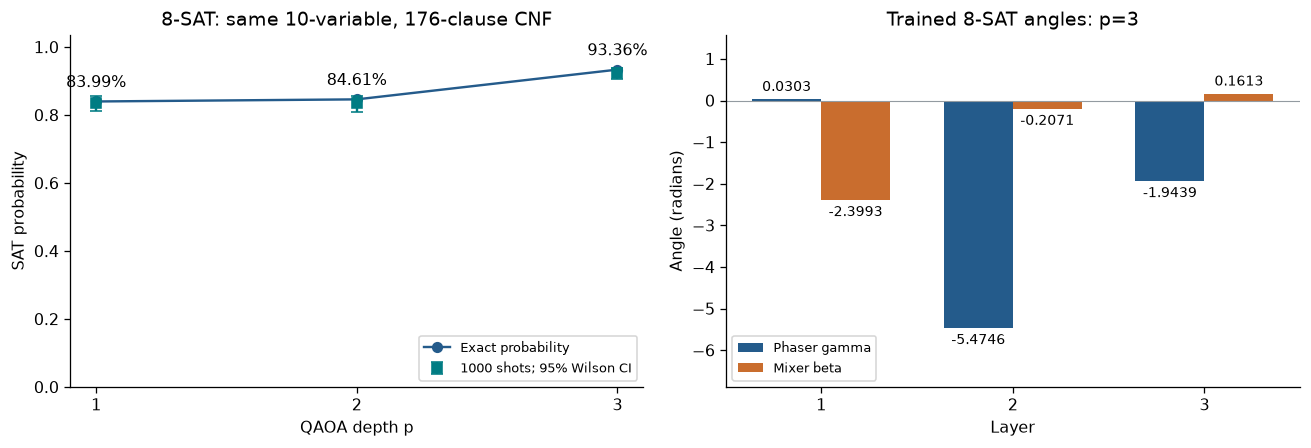

In [10]:
all_angles = read_rows(PROJECT/RESULT_ROOT/'pretrain/trained_angles.csv')
training_records = read_rows(PROJECT/RESULT_ROOT/'pretrain/training_runs.csv')
p_values = sorted({int(row['p']) for row in all_angles})
depth_rows, angle_rows = [], []
for depth in p_values:
    rows = sorted([row for row in all_angles if int(row['p']) == depth], key=lambda row: int(row['layer']))
    gs = np.array([float(row['gamma_rad']) for row in rows])
    bs = np.array([float(row['beta_rad']) for row in rows])
    vector = Statevector.from_instruction(qaoa_circuit(N, clauses, gs, bs)).data
    probability = float(np.sum(np.abs(vector[good])**2))
    successes = int(sample_counts(vector, SHOTS, SHOT_SEED+1000+depth)[good].sum())
    low, high = wilson(successes, SHOTS)
    depth_rows.append({'p': depth, 'P_exact': probability, 'SAT_shots': successes,
                       'shots': SHOTS, 'frequency': successes/SHOTS, 'CI_low': low, 'CI_high': high})
    angle_rows += [{'p': depth, 'layer': int(row['layer']),
                    'gamma_rad': float(row['gamma_rad']), 'beta_rad': float(row['beta_rad'])} for row in rows]
write_rows('01_depth_success.csv', depth_rows)
write_rows('01_angles.csv', angle_rows)
show_rows(angle_rows)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].plot(p_values, [r['P_exact'] for r in depth_rows], 'o-', color=COLORS['QAOA'], label='Exact probability')
observed = np.array([r['frequency'] for r in depth_rows])
errors = np.array([observed-[r['CI_low'] for r in depth_rows], [r['CI_high'] for r in depth_rows]-observed])
axes[0].errorbar(p_values, observed, yerr=np.maximum(errors, 0), fmt='s', capsize=4,
                 color=COLORS['AA adjusted'], label='1000 shots; 95% Wilson CI')
for row in depth_rows:
    axes[0].annotate(f"{100*row['P_exact']:.2f}%", (row['p'], row['P_exact']),
                     xytext=(0, 9), textcoords='offset points', ha='center')
axes[0].set(xlabel='QAOA depth p', ylabel='SAT probability', ylim=(0, 1.035),
             xticks=p_values, title='8-SAT: same 10-variable, 176-clause CNF')
axes[0].legend(fontsize=8, loc='lower right')
layers = np.arange(1, P+1)
for offset, values, label, color in [(-.18, gammas, 'Phaser gamma', COLORS['QAOA']),
                                   (.18, betas, 'Mixer beta', COLORS['AA fixed'])]:
    bars = axes[1].bar(layers+offset, values, width=.36, label=label, color=color)
    axes[1].bar_label(bars, labels=[f'{v:.4f}' for v in values], padding=3, fontsize=9)
axes[1].axhline(0, color='#939ba1', linewidth=.7)
axes[1].set(xlabel='Layer', ylabel='Angle (radians)', xticks=layers, title=f'Trained 8-SAT angles: p={P}')
axes[1].margins(y=.25)
axes[1].legend(fontsize=8)
fig.tight_layout()
save_plot(fig, '01_depth_and_angles')

## 6. 三种深度的 AA 成功概率：p=1、2、3

三幅图使用同一份 10 变量、176 个 8-literal 子句 CNF，分别读取 Pretrain 已训练的 **p=1、2、3** 参数并构建各自的 QAOA 状态，再对各自状态做 AA。

$$\theta_p=\arcsin\sqrt{P_0^{(p)}},\qquad
P_R^{(p)}=\sin^2((2R+1)\theta_p).$$

每个深度扫描整数 $R=0\ldots12$，每个点 **1000 shots**，并显示精确概率与 95% 置信区间；三种深度合计 39000 次扫描 shots。**aa-fixed 均为 R=1**，**aa-adjusted** 分别按各自扫描结果选择 R。

不同深度的初始成功率不同，AA 的旋转效果也不同，概率会随轮数振荡。后面的主电路与统计继续使用 **p=3、aa-fixed R=1**，并沿用原来的主实例抽样种子。

<table><thead><tr><th>p</th><th>initial_P_exact</th><th>aa_fixed_R</th><th>aa_adjusted_R</th><th>shots_per_R</th><th>scan_shots</th></tr></thead><tbody><tr><td>1</td><td>0.8398836297064205</td><td>1</td><td>11</td><td>1000</td><td>13000</td></tr><tr><td>2</td><td>0.8460731498783622</td><td>1</td><td>11</td><td>1000</td><td>13000</td></tr><tr><td>3</td><td>0.9336221391937229</td><td>1</td><td>12</td><td>1000</td><td>13000</td></tr></tbody></table>

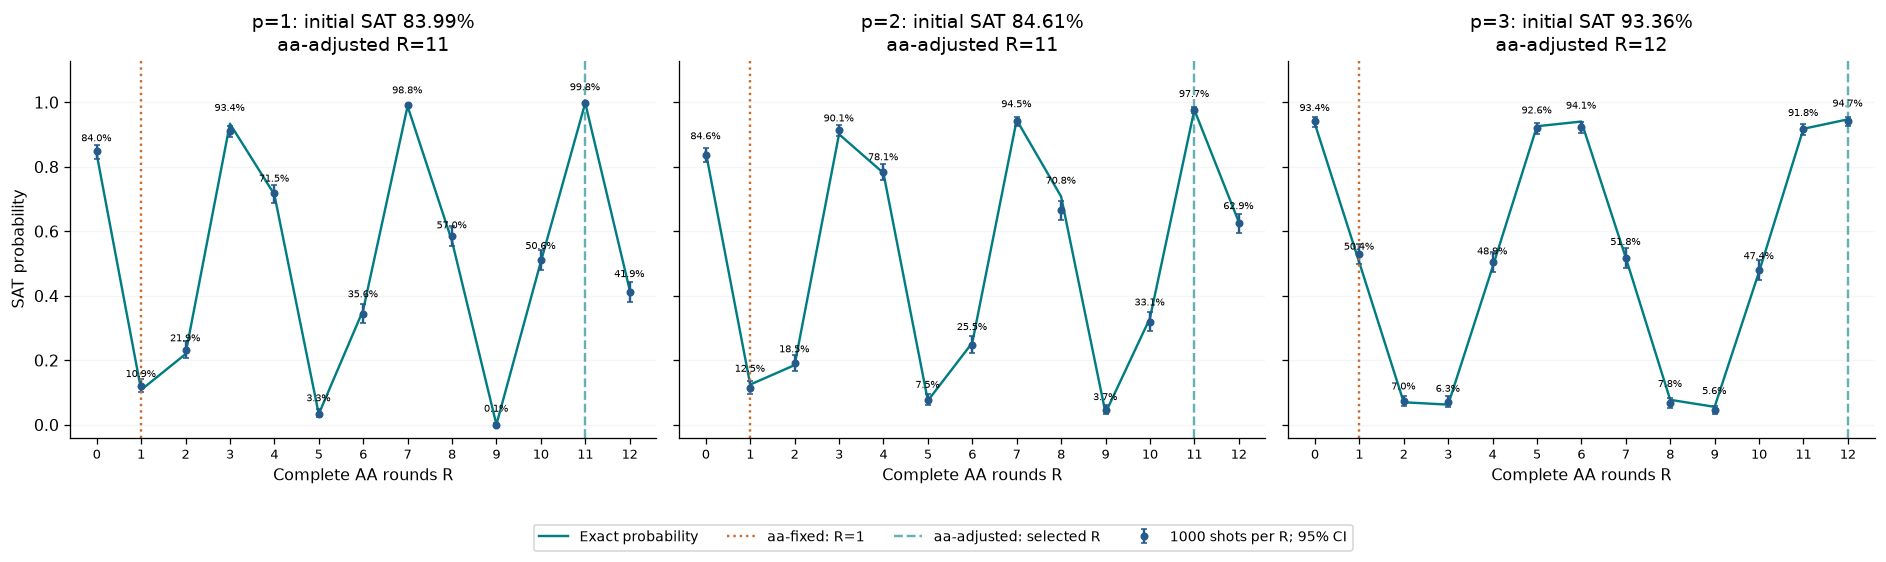

In [11]:
AA_DEPTHS = [1, 2, 3]
aa_depth_results, all_depth_round_rows, depth_round_settings = {}, [], []
for depth in AA_DEPTHS:
    depth_angles = sorted([row for row in all_angles if int(row['p']) == depth],
                          key=lambda row: int(row['layer']))
    assert [int(row['layer']) for row in depth_angles] == list(range(1, depth+1))
    depth_gammas = np.array([float(row['gamma_rad']) for row in depth_angles])
    depth_betas = np.array([float(row['beta_rad']) for row in depth_angles])
    depth_state = Statevector.from_instruction(
        qaoa_circuit(N, clauses, depth_gammas, depth_betas)).data
    depth_initial = float(np.sum(np.abs(depth_state[good])**2))
    depth_curve, depth_states = [], {}
    for r in range(R_MAX+1):
        state_r = amplify_state(depth_state, good, r)
        depth_states[r] = state_r
        exact = float(np.sum(np.abs(state_r[good])**2))
        assert np.isclose(exact, aa_success(depth_initial, r), atol=1e-10)
        seed_r = SHOT_SEED+100+r if depth == P else SHOT_SEED+10000*depth+100+r
        successes = int(sample_counts(state_r, SHOTS, seed_r)[good].sum())
        low, high = wilson(successes, SHOTS)
        row = {'R': r, 'P_exact': exact, 'SAT_shots': successes, 'shots': SHOTS,
               'frequency': successes/SHOTS, 'CI_low': low, 'CI_high': high,
               'A_or_A_dagger_calls': 2*r+1}
        depth_curve.append(row)
        all_depth_round_rows.append({'p': depth, **row})
    depth_adjusted = max(range(R_MAX+1), key=lambda r: (depth_curve[r]['frequency'], -r))
    aa_depth_results[depth] = {'P0': depth_initial, 'curve': depth_curve,
                               'states': depth_states, 'R_adjusted': depth_adjusted}
    depth_round_settings.append({'p': depth, 'initial_P_exact': depth_initial,
                                  'aa_fixed_R': R_FIXED, 'aa_adjusted_R': depth_adjusted,
                                  'shots_per_R': SHOTS, 'scan_shots': SHOTS*(R_MAX+1)})

# 下游变量继续对应主电路 p=3，其他深度仅作对照。
main_aa = aa_depth_results[P]
assert np.isclose(main_aa['P0'], P0, atol=1e-10)
round_rows, states_by_r = main_aa['curve'], main_aa['states']
R_ADJUSTED = main_aa['R_adjusted']
fixed_state, adjusted_state = states_by_r[R_FIXED], states_by_r[R_ADJUSTED]
P_FIXED = float(aa_success(P0, R_FIXED))
P_ADJUSTED = float(aa_success(P0, R_ADJUSTED))
R_APPROX = float(np.pi/(4*np.sqrt(P0)))
R_PAPER_FLOOR = int(np.floor(R_APPROX))
write_rows('02_success_vs_R_1000_shots_each.csv', round_rows)
write_rows('02_success_vs_R_by_depth_1000_shots_each.csv', all_depth_round_rows)
show_rows(depth_round_settings)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9), sharex=True, sharey=True)
integer_r = np.arange(R_MAX+1)
for ax, depth in zip(axes, AA_DEPTHS):
    result = aa_depth_results[depth]
    curve = result['curve']
    exact_values = np.array([row['P_exact'] for row in curve])
    observed = np.array([row['frequency'] for row in curve])
    error = np.array([observed-[row['CI_low'] for row in curve],
                      [row['CI_high'] for row in curve]-observed])
    ax.plot(integer_r, exact_values, '-', color=COLORS['AA adjusted'], label='Exact probability')
    ax.errorbar(integer_r, observed, yerr=np.maximum(error, 0), fmt='o', markersize=4,
                 color=COLORS['QAOA'], capsize=2, label='1000 shots per R; 95% CI')
    for row in curve:
        ax.annotate(f"{100*row['P_exact']:.1f}%", (row['R'], row['P_exact']), xytext=(0, 8),
                     textcoords='offset points', ha='center', fontsize=6.5)
    ax.axvline(R_FIXED, color=COLORS['AA fixed'], linestyle=':', label='aa-fixed: R=1')
    ax.axvline(result['R_adjusted'], color=COLORS['AA adjusted'], linestyle='--', alpha=.6,
                label='aa-adjusted: selected R')
    ax.set(title=f"p={depth}: initial SAT {100*result['P0']:.2f}%\naa-adjusted R={result['R_adjusted']}",
            xlabel='Complete AA rounds R', xticks=integer_r, ylim=(-.04, 1.13))
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='y', alpha=.12)
axes[0].set_ylabel('SAT probability')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.5, 0), ncol=4, fontsize=9)
fig.tight_layout(rect=(0, .10, 1, 1))
save_plot(fig, '02_AA_success_and_cost_vs_R')


## 7. Sparrow 的真实输出与 QAOA 输出解

运行本机 Sparrow，并按原始 8 条子句逐个核验；QAOA 与 AA 对每个固定设置独立抽样 1000 次。比特串从左到右为 $x_{10}\ldots x_1$。**不同字符串只要满足全部子句，都是正确解。**

Sparrow: 250/1000 verified runs


Sparrow: 500/1000 verified runs


Sparrow: 750/1000 verified runs


Sparrow: 1000/1000 verified runs


Sparrow example, seed 1:
s SATISFIABLE
v 1 2 -3 -4 5 -6 -7 -8 -9 -10 0


<table><thead><tr><th>method</th><th>R</th><th>SAT_outputs</th><th>trials_or_shots</th><th>frequency</th><th>P_exact</th><th>CI_low</th><th>CI_high</th></tr></thead><tbody><tr><td>QAOA</td><td>0</td><td>935</td><td>1000</td><td>0.935</td><td>0.9336221391937229</td><td>0.9179944906866292</td><td>0.948676229430938</td></tr><tr><td>AA fixed</td><td>1</td><td>518</td><td>1000</td><td>0.518</td><td>0.5036643471220518</td><td>0.48702069136344844</td><td>0.5488415453310715</td></tr><tr><td>AA adjusted</td><td>12</td><td>941</td><td>1000</td><td>0.941</td><td>0.947464163330728</td><td>0.9246390972285408</td><td>0.9539857017871995</td></tr><tr><td>Sparrow</td><td></td><td>1000</td><td>1000</td><td>1.0</td><td>None</td><td>0.996173241514445</td><td>1.0</td></tr></tbody></table>

<table><thead><tr><th>method</th><th>most_frequent_output</th><th>SAT</th><th>count_in_1000</th><th>observed_output_P</th><th>exact_output_P</th></tr></thead><tbody><tr><td>Sparrow</td><td>0101010100</td><td>True</td><td>9</td><td>0.009</td><td>empirical only</td></tr><tr><td>QAOA</td><td>0001000110</td><td>True</td><td>8</td><td>0.008</td><td>0.0016977714610812706</td></tr><tr><td>AA fixed</td><td>1010110110</td><td>False</td><td>13</td><td>0.013</td><td>0.006728996613219686</td></tr><tr><td>AA adjusted</td><td>0100001001</td><td>True</td><td>7</td><td>0.007</td><td>0.002142171463292576</td></tr></tbody></table>

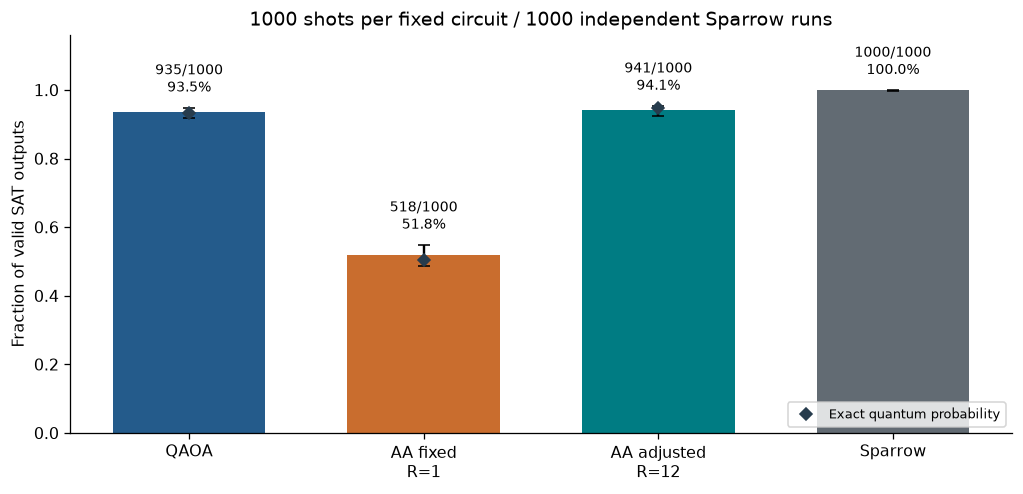

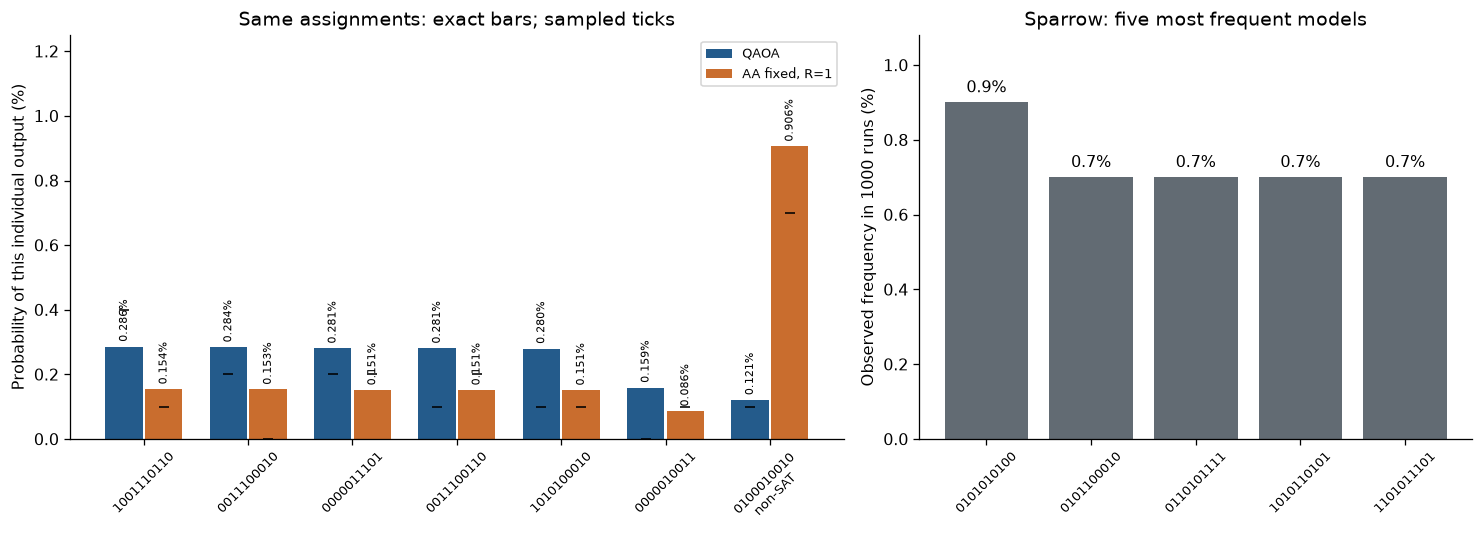

In [12]:
sparrow_results = solver_batch(N, clauses, SPARROW_RUNS, progress=True)
sparrow_counts = np.zeros(1 << N, dtype=np.int64)
for result in sparrow_results:
    if result['valid']:
        sparrow_counts[result['state']] += 1
write_rows('04_sparrow_1000_runs.csv', [{key: value for key, value in result.items()
                                       if key != 'stdout'} for result in sparrow_results])
(TABLES/'04_sparrow_example.txt').write_text(sparrow_results[0]['stdout'], encoding='utf-8')
print('Sparrow example, seed 1:\n'+sparrow_results[0]['stdout'].strip())

q_counts = sample_counts(psi, SHOTS, SHOT_SEED)
fixed_counts = sample_counts(fixed_state, SHOTS, SHOT_SEED+1)
adjusted_counts = sample_counts(adjusted_state, SHOTS, SHOT_SEED+2)
prob_q, prob_fixed, prob_adjusted = np.abs(psi)**2, np.abs(fixed_state)**2, np.abs(adjusted_state)**2
accuracy_rows = []
for label, count, exact in [('QAOA', q_counts, P0), ('AA fixed', fixed_counts, P_FIXED),
                            ('AA adjusted', adjusted_counts, P_ADJUSTED), ('Sparrow', sparrow_counts, None)]:
    successes = int(count[good].sum())
    low, high = wilson(successes, SHOTS)
    accuracy_rows.append({'method': label, 'R': {'QAOA': 0, 'AA fixed': R_FIXED,
                                               'AA adjusted': R_ADJUSTED, 'Sparrow': ''}[label],
                          'SAT_outputs': successes, 'trials_or_shots': SHOTS,
                          'frequency': successes/SHOTS, 'P_exact': exact,
                          'CI_low': low, 'CI_high': high})
write_rows('04_success_accuracy.csv', accuracy_rows)
show_rows(accuracy_rows)
output_rows = []
for value in range(1 << N):
    output_rows.append({'state': bitstring(value), 'state_index': value, 'SAT': bool(good[value]),
                        'QAOA_P': float(prob_q[value]), 'QAOA_count': int(q_counts[value]),
                        'AA_fixed_P': float(prob_fixed[value]), 'AA_fixed_count': int(fixed_counts[value]),
                        'AA_fixed_amplitude_real': float(fixed_state[value].real),
                        'AA_fixed_amplitude_imag': float(fixed_state[value].imag),
                        'AA_fixed_amplitude_magnitude': float(abs(fixed_state[value])),
                        'AA_adjusted_P': float(prob_adjusted[value]), 'AA_adjusted_count': int(adjusted_counts[value]),
                        'Sparrow_count': int(sparrow_counts[value]),
                        'Sparrow_frequency': float(sparrow_counts[value]/SPARROW_RUNS),
                        'QAOA_amplitude_real': float(psi[value].real),
                        'QAOA_amplitude_imag': float(psi[value].imag),
                        'QAOA_amplitude_magnitude': float(abs(psi[value])),
                        'AA_adjusted_amplitude_real': float(adjusted_state[value].real),
                        'AA_adjusted_amplitude_imag': float(adjusted_state[value].imag),
                        'AA_adjusted_amplitude_magnitude': float(abs(adjusted_state[value]))})
write_rows('04_all_1024_state_probabilities_amplitudes_counts.csv', output_rows)
comparison_rows = []
for label, counts, probability in [('Sparrow', sparrow_counts, None), ('QAOA', q_counts, prob_q),
                                   ('AA fixed', fixed_counts, prob_fixed),
                                   ('AA adjusted', adjusted_counts, prob_adjusted)]:
    value = int(np.argmax(counts))
    comparison_rows.append({'method': label, 'most_frequent_output': bitstring(value),
                            'SAT': is_solution(value, clauses), 'count_in_1000': int(counts[value]),
                            'observed_output_P': float(counts[value]/SHOTS),
                            'exact_output_P': float(probability[value]) if probability is not None else 'empirical only'})
show_rows(comparison_rows)
write_rows('04_output_solution_comparison.csv', comparison_rows)

fig, ax = plt.subplots(figsize=(9, 4.4))
xloc = np.arange(len(accuracy_rows))
frequency = np.array([row['frequency'] for row in accuracy_rows])
error = np.array([frequency-[r['CI_low'] for r in accuracy_rows], [r['CI_high'] for r in accuracy_rows]-frequency])
bars = ax.bar(xloc, frequency, color=[COLORS[row['method']] for row in accuracy_rows],
               yerr=np.maximum(error, 0), capsize=4, width=.65)
ax.bar_label(bars, labels=[f"{r['SAT_outputs']}/1000\n{100*r['frequency']:.1f}%" for r in accuracy_rows],
              padding=7, fontsize=9)
ax.plot(xloc[:3], [P0, P_FIXED, P_ADJUSTED], 'D', color='#273c4d', markersize=5, label='Exact quantum probability')
ax.set(xticks=xloc, xticklabels=['QAOA', f'AA fixed\nR={R_FIXED}', f'AA adjusted\nR={R_ADJUSTED}', 'Sparrow'],
        ylabel='Fraction of valid SAT outputs', ylim=(0, 1.16),
        title='1000 shots per fixed circuit / 1000 independent Sparrow runs')
ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
save_plot(fig, '04_success_accuracy_1000')

sparrow_top = np.argsort(-sparrow_counts, kind='stable')[:5]
sparrow_example_state = next(row['state'] for row in sparrow_results if row['valid'])
best_non_sat = int(np.flatnonzero(~good)[np.argmax(prob_q[~good])])
shown = list(dict.fromkeys([int(v) for v in np.argsort(-prob_q)[:5]]+
                           [int(sparrow_example_state), best_non_sat]))
positions = np.arange(len(shown))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.4, 1]})
for offset, exact, counts, label, color in [(-.19, prob_q, q_counts, 'QAOA', COLORS['QAOA']),
    (.19, prob_fixed, fixed_counts, f'AA fixed, R={R_FIXED}', COLORS['AA fixed'])]:
    bars = axes[0].bar(positions+offset, exact[shown]*100, width=.36, label=label, color=color)
    axes[0].bar_label(bars, labels=[f'{100*v:.3f}%' for v in exact[shown]], padding=3, fontsize=7, rotation=90)
    axes[0].plot(positions+offset, counts[shown]/SHOTS*100, 'k_', markersize=6)
axes[0].set(xticks=positions, xticklabels=[bitstring(v)+('' if good[v] else '\nnon-SAT') for v in shown],
             ylabel='Probability of this individual output (%)', title='Same assignments: exact bars; sampled ticks')
axes[0].tick_params(axis='x', labelrotation=45, labelsize=8)
axes[0].margins(y=.38)
axes[0].legend(fontsize=8)
bars = axes[1].bar(np.arange(len(sparrow_top)), sparrow_counts[sparrow_top]/SPARROW_RUNS*100, color=COLORS['Sparrow'])
axes[1].bar_label(bars, labels=[f'{100*sparrow_counts[v]/SPARROW_RUNS:.1f}%' for v in sparrow_top], padding=4)
axes[1].set(xticks=np.arange(len(sparrow_top)), xticklabels=[bitstring(v) for v in sparrow_top],
             ylabel='Observed frequency in 1000 runs (%)', title='Sparrow: five most frequent models')
axes[1].tick_params(axis='x', labelrotation=45, labelsize=8)
axes[1].margins(y=.2)
fig.tight_layout()
save_plot(fig, '05_output_solution_probabilities')

## 8. Amplitude spectrum：解的振幅有多大？

$$P(x)=|\alpha_x|^2,\qquad P(\mathrm{SAT})=\sum_{x\text{ 为满足解}}|\alpha_x|^2.$$

前两幅柱图比较 QAOA 与**固定一轮 AA（R=1）**，使用**相同赋值**：QAOA 振幅最大的 12 个答案，加上最强的非满足态。第三幅按真实振幅排序显示全部 1024 个态，并区分 SAT / non-SAT。显示真实大小，不把满足解人工移到最大位置。

Largest QAOA amplitude: 1001110110, SAT=True, |alpha|=0.053504, P(output)=0.2863%.
Total SAT probability: QAOA=93.3622%; fixed AA(R=1)=50.3664%; scan-selected AA(R=12)=94.7464%.


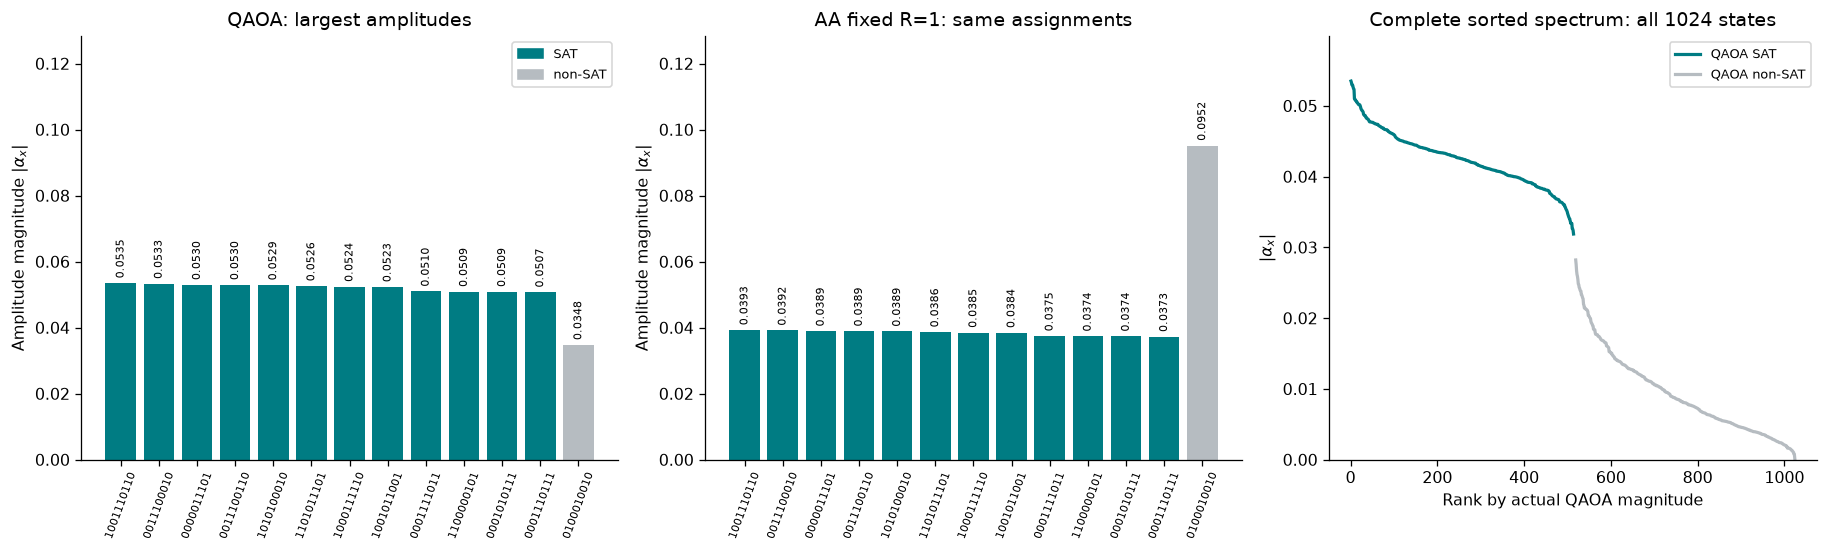

In [13]:
magnitude_q, magnitude_aa = np.abs(psi), np.abs(fixed_state)
ranked = np.argsort(-magnitude_q, kind='stable')
top_states = list(dict.fromkeys([int(v) for v in ranked[:12]]+[best_non_sat]))
maximum_state = int(ranked[0])
print(f'Largest QAOA amplitude: {bitstring(maximum_state)}, SAT={good[maximum_state]}, '
      f'|alpha|={magnitude_q[maximum_state]:.6f}, P(output)={100*prob_q[maximum_state]:.4f}%.')
print(f'Total SAT probability: QAOA={100*P0:.4f}%; fixed AA(R={R_FIXED})={100*P_FIXED:.4f}%; '
      f'scan-selected AA(R={R_ADJUSTED})={100*P_ADJUSTED:.4f}%.')
write_rows('05_ranked_amplitude_spectrum.csv', [
    {'rank': rank, 'state': bitstring(value), 'SAT': bool(good[value]),
     'QAOA_abs_amplitude': float(magnitude_q[value]), 'QAOA_P': float(prob_q[value]),
     'AA_fixed_abs_amplitude': float(magnitude_aa[value]), 'AA_fixed_P': float(prob_fixed[value]),
     'AA_scan_abs_amplitude': float(abs(adjusted_state[value])), 'AA_scan_P': float(prob_adjusted[value])}
    for rank, value in enumerate(ranked, 1)])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9), gridspec_kw={'width_ratios': [1.1, 1.1, 1]})
colors = [COLORS['AA adjusted'] if good[value] else COLORS['non-SAT'] for value in top_states]
for ax, values, title in [(axes[0], magnitude_q, 'QAOA: largest amplitudes'),
                           (axes[1], magnitude_aa, f'AA fixed R={R_FIXED}: same assignments')]:
    bars = ax.bar(np.arange(len(top_states)), values[top_states], color=colors)
    ax.bar_label(bars, labels=[f'{v:.4f}' for v in values[top_states]], padding=3, rotation=90, fontsize=7)
    ax.set(xticks=np.arange(len(top_states)), xticklabels=[bitstring(v) for v in top_states],
            ylabel=r'Amplitude magnitude $|\alpha_x|$', title=title)
    ax.tick_params(axis='x', labelrotation=70, labelsize=7)
    ax.set_ylim(0, max(magnitude_q.max(), magnitude_aa.max())*1.35)
axes[0].legend(handles=[Patch(color=COLORS['AA adjusted'], label='SAT'),
                        Patch(color=COLORS['non-SAT'], label='non-SAT')], fontsize=8)
for mask, color, label in [(good, COLORS['AA adjusted'], 'SAT'), (~good, COLORS['non-SAT'], 'non-SAT')]:
    axes[2].plot(np.arange(1, len(ranked)+1), np.where(mask[ranked], magnitude_q[ranked], np.nan),
                  color=color, label='QAOA '+label, linewidth=2)
axes[2].set(xlabel='Rank by actual QAOA magnitude', ylabel=r'$|\alpha_x|$',
             title='Complete sorted spectrum: all 1024 states', ylim=(0, magnitude_q.max()*1.12))
axes[2].legend(fontsize=8)
fig.tight_layout()
save_plot(fig, '06_amplitude_spectrum')

## 9. 四种方法的实测执行时间

统一比较 **QAOA、aa-fixed（R=1）、aa-adjusted、Sparrow**。每次量子模拟都重新制备状态、执行相应轮数的 AA 并测量一次；Sparrow 每次启动并执行一次求解。纵轴直接使用测得的毫秒数，不根据成功概率乘重试次数。各方法的成功率在前面的统计图中单独展示。

左图是单次执行时间，右图是在该时间上加上已记录的训练时间。角度训练后保持不变，执行时不再训练。主实例的训练耗时来自本次 8-SAT Pretrain；计时为精确 NumPy 态矢量与原生 Sparrow 的墙钟时间。每层对角相位预编译、选 R 扫描不计入单次执行时间。Sparrow 计时包含进程启动和输出，CNF 准备与答案核验在计时区间之外。

<table><thead><tr><th>method</th><th>P_success</th><th>execution_median_s</th><th>execution_q25_s</th><th>execution_q75_s</th><th>timed_repeats</th><th>saved_pretrain_s</th><th>training_plus_execution_s</th></tr></thead><tbody><tr><td>QAOA</td><td>0.9336221391937229</td><td>0.00035140000000000003</td><td>0.0003486</td><td>0.00035600000000000003</td><td>21</td><td>0.2828896000282839</td><td>0.2832410000282839</td></tr><tr><td>aa-fixed</td><td>0.5036643471220518</td><td>0.0009106</td><td>0.000894</td><td>0.0009147000000000001</td><td>21</td><td>0.2828896000282839</td><td>0.2838002000282839</td></tr><tr><td>aa-adjusted</td><td>0.947464163330728</td><td>0.0099558</td><td>0.0072798</td><td>0.0100189</td><td>21</td><td>0.2828896000282839</td><td>0.2928454000282839</td></tr><tr><td>Sparrow</td><td>1.0</td><td>0.025124150000000005</td><td>0.024178300000000003</td><td>0.026438025</td><td>1000</td><td>0.0</td><td>0.025124150000000005</td></tr></tbody></table>

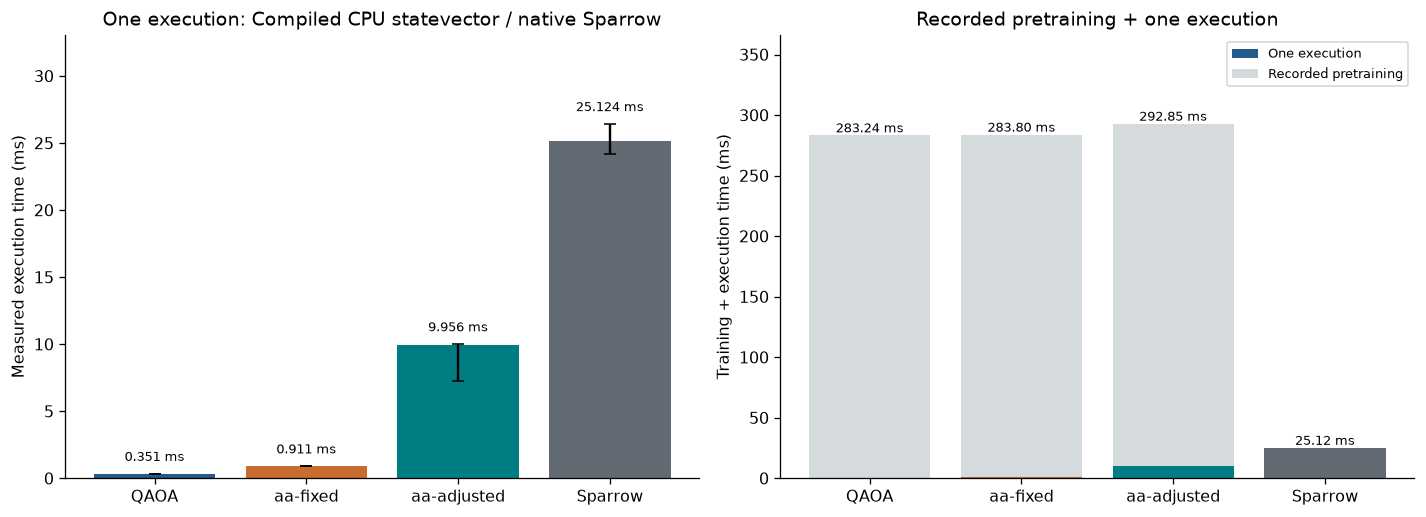

In [14]:
# Verify the timed compiled evolution against the exact AA distribution.
phases=[np.exp(-1j*g*paper_cost_diagonal(N,clauses)) for g in gammas]
compiled=np.zeros(1<<N,dtype=complex);compiled[0]=1
compiled=apply_preparation(compiled,N,phases,betas)
assert np.allclose(compiled,psi,atol=1e-9)
for _ in range(R_ADJUSTED):
    compiled[good]*=-1
    compiled=apply_preparation(compiled,N,phases,betas,inverse=True)
    compiled[0]*=-1
    compiled=apply_preparation(compiled,N,phases,betas)
assert np.allclose(compiled,adjusted_state,atol=1e-8)

q_times = time_simulator(A, good, 0, clauses, 8021, repeats=21)
fixed_times = time_simulator(A, good, R_FIXED, clauses, 8022, repeats=21)
adjusted_times = q_times if R_ADJUSTED == 0 else time_simulator(A, good, R_ADJUSTED, clauses, 8023, repeats=21)
sparrow_times = [row['process_s'] for row in sparrow_results]
saved_pretrain_s = sum(float(row['pretrain_s']) for row in training_records if int(row['p']) <= P)
method_times = {'QAOA': q_times, 'aa-fixed': fixed_times, 'aa-adjusted': adjusted_times, 'Sparrow': sparrow_times}
method_success = {'QAOA': P0, 'aa-fixed': P_FIXED, 'aa-adjusted': P_ADJUSTED,
                  'Sparrow': float(sum(row['valid'] for row in sparrow_results)/SPARROW_RUNS)}
TIME_COLORS = {'QAOA': COLORS['QAOA'], 'aa-fixed': COLORS['AA fixed'],
               'aa-adjusted': COLORS['AA adjusted'], 'Sparrow': COLORS['Sparrow']}

# Summarize measured execution times directly.
time_rows, time_raw = [], []
for method, values in method_times.items():
    median = float(np.median(values))
    pretrain = 0. if method == 'Sparrow' else saved_pretrain_s
    time_rows.append({'method': method, 'P_success': method_success[method],
                      'execution_median_s': median, 'execution_q25_s': float(np.quantile(values, .25)),
                      'execution_q75_s': float(np.quantile(values, .75)), 'timed_repeats': len(values),
                      'saved_pretrain_s': pretrain, 'training_plus_execution_s': pretrain+median})
    time_raw += [{'method': method, 'repetition': i+1, 'attempt_s': value}
                 for i, value in enumerate(values)]
write_rows('06_main_time_components.csv', time_rows)
write_rows('06_main_time_repeats.csv', time_raw)
show_rows(time_rows)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
positions = np.arange(len(time_rows))
labels = [row['method'] for row in time_rows]
median = np.array([row['execution_median_s']*1000 for row in time_rows])
error = np.array([median-[r['execution_q25_s']*1000 for r in time_rows],
                  [r['execution_q75_s']*1000 for r in time_rows]-median])
bars = axes[0].bar(positions, median, color=[TIME_COLORS[row['method']] for row in time_rows],
                    yerr=np.maximum(error, 0), capsize=4)
axes[0].bar_label(bars, labels=[f'{v:.3f} ms' for v in median], padding=6, fontsize=8)
axes[0].set(xticks=positions, xticklabels=labels, ylabel='Measured execution time (ms)',
             title='One execution: Compiled CPU statevector / native Sparrow')
axes[0].margins(y=.25)
pretrain = np.array([row['saved_pretrain_s']*1000 for row in time_rows])
axes[1].bar(positions, median, color=[TIME_COLORS[row['method']] for row in time_rows], label='One execution')
axes[1].bar(positions, pretrain, bottom=median, color='#d5dadd', label='Recorded pretraining')
for i, value in enumerate(median+pretrain):
    axes[1].text(i, value, f'{value:.2f} ms', ha='center', va='bottom', fontsize=8)
axes[1].set(xticks=positions, xticklabels=labels, ylabel='Training + execution time (ms)',
             title='Recorded pretraining + one execution')
axes[1].margins(y=.25)
axes[1].legend(fontsize=8)
fig.tight_layout()
save_plot(fig, '07_main_runtime_comparison')

## 10. Crossover time：四种方法的运行时间交点

四条曲线统一为 **QAOA、aa-fixed、aa-adjusted、Sparrow**。主 QAOA 为三层，aa-fixed 固定一轮；aa-adjusted 在每份实例的 $R=0\ldots12$ 中调整轮数。规模扫描采用小实例模拟得到的精确成功率选择 aa-adjusted 的 R。

横轴为变量数 $n=8,9,10,11,12$，每个规模 3 份 CNF，$m/n\approx17.6$。纵轴直接使用实测运行时间（ms），不作成功率重试换算。左图比较单次执行时间，右图加上训练和预处理时间；曲线是三个实例的中位数，阴影为四分位范围。

方法曲线与 Sparrow 相交时，同时读出**交点规模 $n_*$**和**crossover time $t_*$**：
$$T_{\rm method}(n_*)=T_{\rm Sparrow}(n_*)=t_*.$$
交点仅在实测整数规模之间插值；没有交点就报告未观察到。成功概率另见前面的图。时间是本机编译态矢量模拟与原生 Sparrow 的执行耗时。

规模扫描对每份公式使用独立训练种子重新拟合。n=10 的第一份复用主 CNF，但重新训练，因此它的角度与成功率不必与主实验完全相同。

Scan n=8, m=141, instance 1/3: P0=0.9888, R_fixed=1, R_adjusted=0, Sparrow=23.273 ms


Scan n=8, m=141, instance 2/3: P0=0.9844, R_fixed=1, R_adjusted=12, Sparrow=23.205 ms


Scan n=8, m=141, instance 3/3: P0=0.9707, R_fixed=1, R_adjusted=9, Sparrow=22.836 ms


Scan n=9, m=158, instance 1/3: P0=0.9295, R_fixed=1, R_adjusted=11, Sparrow=23.516 ms


Scan n=9, m=158, instance 2/3: P0=0.8423, R_fixed=1, R_adjusted=11, Sparrow=20.184 ms


Scan n=9, m=158, instance 3/3: P0=0.9579, R_fixed=1, R_adjusted=7, Sparrow=24.259 ms


... (6 outputs left out)

Scan n=12, m=211, instance 1/3: P0=0.9441, R_fixed=1, R_adjusted=6, Sparrow=22.911 ms


Scan n=12, m=211, instance 2/3: P0=0.9311, R_fixed=1, R_adjusted=11, Sparrow=23.712 ms


Scan n=12, m=211, instance 3/3: P0=0.8091, R_fixed=1, R_adjusted=3, Sparrow=22.812 ms


execution: QAOA / Sparrow: no crossing in measured range.
execution: aa-fixed / Sparrow: no crossing in measured range.
execution: aa-adjusted / Sparrow: no crossing in measured range.
training_plus_execution: QAOA / Sparrow: no crossing in measured range.
training_plus_execution: aa-fixed / Sparrow: no crossing in measured range.
training_plus_execution: aa-adjusted / Sparrow: no crossing in measured range.


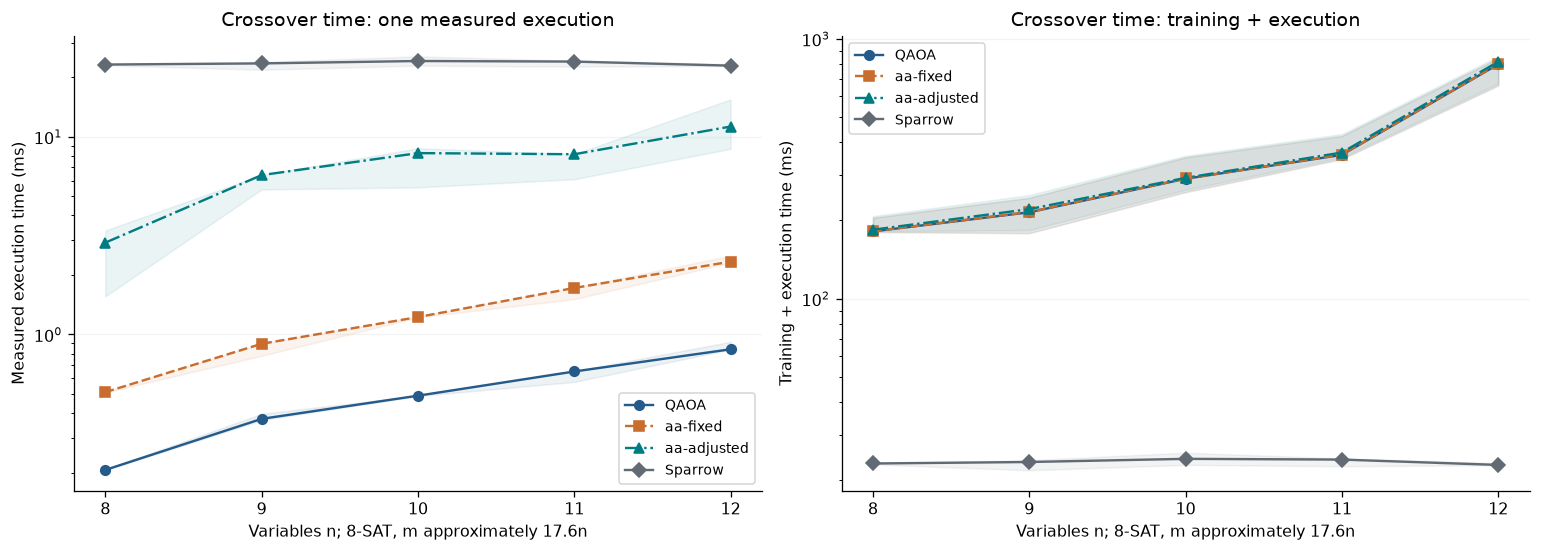

In [15]:
sweep_rows, sweep_solver_raw, sweep_timing_raw, sweep_instances = [], [], [], []
for n in SWEEP_N:
    m = max(1, int(round(M/N*n)))
    for instance in range(SWEEP_INSTANCES):
        seed = 20261116+100*n+instance
        formula = clauses if n == N and instance == 0 else generate_satisfiable(n, m, seed)
        setup_start = time.perf_counter()
        diagonal = paper_cost_diagonal(n, formula)
        mask = diagonal == -m
        setup_s = time.perf_counter()-setup_start
        warm = None
        train_s = 0.
        for depth in range(1, P+1):
            fit = train_qaoa(n, diagonal, mask, depth, TRAIN_SEED+seed+depth,
                             restarts=RESTARTS, maxiter=MAXITER, warm=warm)
            train_s += fit['train_time_s']
            warm = fit
        circuit = qaoa_circuit(n, formula, fit['gammas'], fit['betas'])
        vector = Statevector.from_instruction(circuit).data
        assert np.allclose(vector, fit['state'], atol=1e-9)
        initial = float(np.sum(np.abs(vector[mask])**2))
        r_fixed = R_FIXED
        r_adjusted = max(range(R_MAX+1), key=lambda r: (float(aa_success(initial, r)), -r))
        quantum_times = time_simulator(circuit, mask, 0, formula, seed)
        fixed_times = quantum_times if r_fixed == 0 else time_simulator(circuit, mask, r_fixed, formula, seed+1)
        scan_times = quantum_times if r_adjusted == 0 else (
            fixed_times if r_adjusted == r_fixed else time_simulator(circuit, mask, r_adjusted, formula, seed+2))
        native = solver_batch(n, formula, SWEEP_SPARROW_RUNS, seed_base=seed)
        native_success = float(np.mean([row['valid'] for row in native]))
        native_times = [row['process_s'] for row in native]
        times = {'QAOA': quantum_times, 'aa-fixed': fixed_times,
                  'aa-adjusted': scan_times, 'Sparrow': native_times}
        success = {'QAOA': initial, 'aa-fixed': float(aa_success(initial, r_fixed)),
                    'aa-adjusted': float(aa_success(initial, r_adjusted)), 'Sparrow': native_success}
        row = {'n': n, 'm': m, 'instance': instance, 'seed': seed, 'p': P,
                'R_fixed': r_fixed, 'R_adjusted': r_adjusted, 'preprocess_s': setup_s, 'train_s': train_s}
        for method, values in times.items():
            attempt_s = float(np.median(values))
            total_s = attempt_s+(setup_s+train_s if method != 'Sparrow' else 0)
            row[method+'_P'] = success[method]
            row[method+'_attempt_s'] = attempt_s
            row[method+'_execution_s'] = attempt_s
            row[method+'_training_plus_execution_s'] = total_s
            sweep_timing_raw += [{'n': n, 'instance': instance, 'method': method,
                                  'repetition': i+1, 'attempt_s': value} for i, value in enumerate(values)]
        sweep_rows.append(row)
        sweep_solver_raw += [{'n': n, 'instance': instance, **{key: value for key, value in result.items()
                                                               if key != 'stdout'}} for result in native]
        sweep_instances.append({'n': n, 'm': m, 'instance': instance, 'seed': seed,
                                 'clauses': formula, 'gammas': fit['gammas'].tolist(),
                                 'betas': fit['betas'].tolist()})
        write_rows('07_crossover_instances.csv', sweep_rows)
        print(f'Scan n={n}, m={m}, instance {instance+1}/{SWEEP_INSTANCES}: '
              f'P0={initial:.4f}, R_fixed={r_fixed}, R_adjusted={r_adjusted}, '
              f'Sparrow={1000*np.median(native_times):.3f} ms', flush=True)
write_rows('07_crossover_sparrow_raw.csv', sweep_solver_raw)
write_rows('07_crossover_timing_raw.csv', sweep_timing_raw)
(TABLES/'07_crossover_formulas_and_angles.json').write_text(json.dumps(sweep_instances, indent=2), encoding='utf-8')

# Summarize measured crossover times directly.
methods = ['QAOA', 'aa-fixed', 'aa-adjusted', 'Sparrow']
TIME_COLORS = {'QAOA': COLORS['QAOA'], 'aa-fixed': COLORS['AA fixed'],
               'aa-adjusted': COLORS['AA adjusted'], 'Sparrow': COLORS['Sparrow']}
metrics = ['execution', 'training_plus_execution']
crossover_summary = []
for n in SWEEP_N:
    group = [row for row in sweep_rows if row['n'] == n]
    record = {'n': n, 'm': group[0]['m']}
    for method in methods:
        for metric in metrics:
            values = [row[method+'_'+metric+'_s'] for row in group]
            record[method+'_'+metric+'_median_s'] = float(np.median(values))
            record[method+'_'+metric+'_q25_s'] = float(np.quantile(values, .25))
            record[method+'_'+metric+'_q75_s'] = float(np.quantile(values, .75))
    crossover_summary.append(record)
write_rows('07_crossover_summary.csv', crossover_summary)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9))
markers = {'QAOA': 'o-', 'aa-fixed': 's--', 'aa-adjusted': '^-.', 'Sparrow': 'D-'}
crossover_results = {}
crossover_rows = []
for ax, metric in zip(axes, metrics):
    crossover_results[metric] = {}
    classical = [row['Sparrow_'+metric+'_median_s'] for row in crossover_summary]
    for method in methods:
        y = np.array([row[method+'_'+metric+'_median_s'] for row in crossover_summary])
        low = np.array([row[method+'_'+metric+'_q25_s'] for row in crossover_summary])
        high = np.array([row[method+'_'+metric+'_q75_s'] for row in crossover_summary])
        ax.plot(SWEEP_N, y*1000, markers[method], color=TIME_COLORS[method], label=method)
        ax.fill_between(SWEEP_N, low*1000, high*1000, color=TIME_COLORS[method], alpha=.08)
        if method == 'Sparrow':
            continue
        points = crossover_points(SWEEP_N, y, classical)
        crossover_results[metric][method] = points
        if not points:
            crossover_rows.append({'metric': metric, 'method': method,
                                   'interpolated_n': 'NONE', 'crossover_time_ms': 'NONE'})
            print(f'{metric}: {method} / Sparrow: no crossing in measured range.')
        for point in points:
            crossover_rows.append({'metric': metric, 'method': method,
                                   'interpolated_n': point['n'], 'crossover_time_ms': point['time_s']*1000})
            ax.plot(point['n'], point['time_s']*1000, '*', color=TIME_COLORS[method], markersize=12)
            offset = (9, 16) if method == 'aa-fixed' else (9, -35)
            ax.annotate(f"{method}: n~{point['n']:.1f}\n{point['time_s']*1000:.2f} ms",
                         (point['n'], point['time_s']*1000), xytext=offset,
                         textcoords='offset points', fontsize=8,
                         arrowprops={'arrowstyle': '-', 'color': TIME_COLORS[method]})
            print(f"{metric}: {method} / Sparrow: n~{point['n']:.3f}; "
                  f"crossover time~{point['time_s']*1000:.3f} ms (interpolated).")
    ax.set(xlabel='Variables n; 8-SAT, m approximately 17.6n', xticks=SWEEP_N, yscale='log')
    ax.grid(axis='y', alpha=.15)
    ax.legend(fontsize=9)
axes[0].set(title='Crossover time: one measured execution', ylabel='Measured execution time (ms)')
axes[1].set(title='Crossover time: training + execution', ylabel='Training + execution time (ms)')
write_rows('07_crossover_crossings.csv', crossover_rows)
fig.tight_layout()
save_plot(fig, '08_crossover_execution_time')

In [16]:
# 结果保存与必要核验
assert len(sparrow_results) == SPARROW_RUNS
assert len(round_rows) == R_MAX+1
for count in (q_counts, fixed_counts, adjusted_counts):
    assert int(count.sum()) == SHOTS and np.all(count >= 0)
for vector in (psi, fixed_state, adjusted_state):
    assert np.isclose(np.sum(np.abs(vector)**2), 1)
assert len(output_rows) == 1 << N
experiment_summary = {
    'measured_at_Asia_Shanghai': MEASURED_AT, 'n': N, 'm': M, 'k': K, 'p': P,
    'CNF': CNF_NAME, 'cnf_sha256': summary['cnf_sha256'], 'oracle_qubits': full.num_qubits,
    'clause_ancillas': M, 'counter_bits': 0, 'ancilla_method': 'one flag per clause',
    'phase_precompilation_in_execution_time': False, 'R_selection_in_execution_time': False,
    'parameter_source': 'New 8-SAT Pretrain p=3 trained_angles.csv; angles held fixed',
    'gammas': gammas.tolist(), 'betas': betas.tolist(), 'P_QAOA': P0,
    'R_paper_continuous': R_APPROX, 'R_paper_floor': R_PAPER_FLOOR,
    'R_fixed': R_FIXED, 'R_adjusted_from_shot_scan': R_ADJUSTED,
    'P_AA_fixed': P_FIXED, 'P_AA_adjusted': P_ADJUSTED,
    'shots_per_fixed_circuit': SHOTS, 'R_scan_shots': SHOTS*(R_MAX+1),
    'AA_scan_depths': AA_DEPTHS,
    'AA_all_depth_scan_shots': SHOTS*(R_MAX+1)*len(AA_DEPTHS),
    'Sparrow_runs': SPARROW_RUNS, 'Sparrow_valid': int(sparrow_counts.sum()),
    'crossover_points': crossover_results,
    'runtime_metric': 'direct measured wall time per execution',
    'methods': methods,
    'crossover_scope': 'Measured compiled CPU statevector / native Sparrow execution times, without success-probability normalization',
    'saved_main_pretrain_s': saved_pretrain_s,
    'scan_n': SWEEP_N, 'scan_instances_per_n': SWEEP_INSTANCES,
    'scan_sparrow_runs_per_instance': SWEEP_SPARROW_RUNS,
    'python': sys.version.split()[0], 'qiskit': qiskit.__version__,
    'numpy': np.__version__, 'scipy': scipy.__version__,
}
(TABLES/'experiment_summary.json').write_text(json.dumps(experiment_summary, indent=2), encoding='utf-8')
print('PASS: explicit definitions, matching clauses/circuit, normalized amplitudes, 1000-shot statistics, '
      'verified native models and measured timing sweep.')
print('Figure files:', len(list(FIGURES.glob('*.png'))), '| Data directory:', TABLES)

PASS: explicit definitions, matching clauses/circuit, normalized amplitudes, 1000-shot statistics, verified native models and measured timing sweep.
Figure files: 7 | Data directory: C:\Users\yanxi\.codex\.chatgpt-projects\g-p-6ab3fde64d14819191c93e2b0a8fa871\work\eight_sat_n10_m176_20261116\qaoa_aa_3sat\results\8sat_n10_m176\experiments\data


原理来源：[原论文 v1 式 (2)–(7)](https://arxiv.org/html/2504.01897v1)；
[Brassard 等：Amplitude Amplification](https://arxiv.org/abs/quant-ph/0005055)；
[Sparrow 源码](https://github.com/adrianopolus/Sparrow)。优化器、1000-shot 统计、规模扫描与 CPU 计时是这里的本地实验设置。